# 03. Classical Applied Machine Learning Baselines
### Support Vector Machine (RBF) vs. Random Forest
**Course:** Applied Machine Learning & Deep Learning (AML-DL)

---
## 1. Methodology & Algorithm Selection
Using our 1,634-dimensional fixed feature vectors, we train and compare two canonical classical models:
1. **Support Vector Machine (RBF Kernel):** Maximum-margin separation in reproducing kernel Hilbert space with Platt probability calibration.
2. **Random Forest (Ensemble):** 200 balanced decision trees evaluating axis-aligned splits across gradient histograms.


In [1]:
import sys
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

REPO_ROOT = Path("..").resolve()
MODELS_DIR = REPO_ROOT / "models"
SPLITS_DIR = REPO_ROOT / "splits"
FEATURES_PATH = REPO_ROOT / "data" / "features_aml.npz"

with open(SPLITS_DIR / "classes.json", "r") as f:
    meta = json.load(f)
class_names = meta["class_names"]

feat_data = np.load(FEATURES_PATH)
X_train = feat_data["X_train"]
y_train = feat_data["y_train"]
X_val = feat_data["X_val"]
y_val = feat_data["y_val"]
X_test = feat_data["X_test"]
y_test = feat_data["y_test"]


## 2. Load Trained AML Models & Standard Scaler
We load the fitted `StandardScaler`, `aml_svm.joblib`, and `aml_rf.joblib`.


In [2]:
scaler = joblib.load(MODELS_DIR / "aml_scaler.joblib")
svm_model = joblib.load(MODELS_DIR / "aml_svm.joblib")
rf_model = joblib.load(MODELS_DIR / "aml_rf.joblib")

X_test_scaled = scaler.transform(X_test)
svm_preds = svm_model.predict(X_test_scaled)
rf_preds = rf_model.predict(X_test_scaled)

print(f"SVM Test Accuracy:           {accuracy_score(y_test, svm_preds)*100:.2f}% (Macro F1: {f1_score(y_test, svm_preds, average='macro'):.4f})")
print(f"Random Forest Test Accuracy:  {accuracy_score(y_test, rf_preds)*100:.2f}% (Macro F1: {f1_score(y_test, rf_preds, average='macro'):.4f})")


SVM Test Accuracy:           72.75% (Macro F1: 0.7118)
Random Forest Test Accuracy:  74.87% (Macro F1: 0.7405)


## 3. Per-Class Performance Breakdown
Let us compare precision, recall, and F1-score across all 6 categories.


,Model,Class,Precision,Recall,F1_Score,Support
0,SVM,cardboard,72.13,72.13,0.7213,61
1,SVM,glass,75.00,72.00,0.7347,75
2,SVM,metal,66.67,75.41,0.7077,61
3,SVM,paper,81.32,83.15,0.8222,89
4,SVM,plastic,68.12,65.28,0.6667,72
5,SVM,trash,75.00,60.00,0.6667,20
6,Random Forest,cardboard,85.19,75.41,0.8000,61
7,Random Forest,glass,68.67,76.00,0.7215,75
8,Random Forest,metal,79.17,62.30,0.6972,61
9,Random Forest,paper,74.77,93.26,0.8300,89


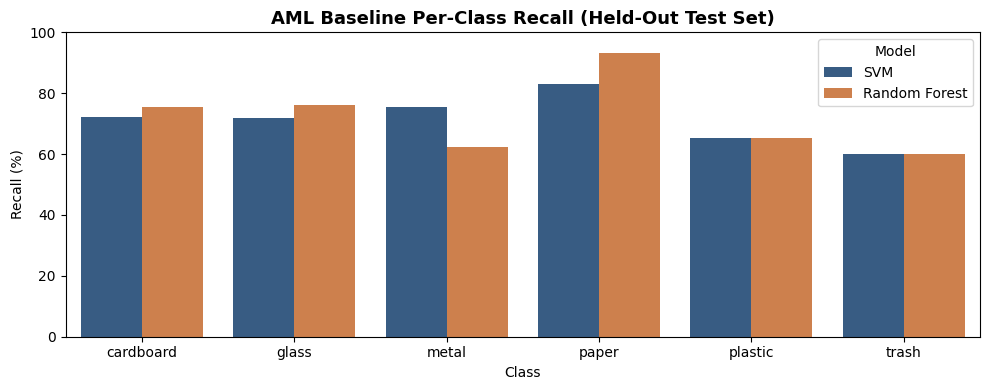

In [3]:
per_class = pd.read_csv(REPO_ROOT / "results" / "metrics" / "per_class_performance.csv")
aml_per_class = per_class[per_class["Model"].isin(["SVM", "Random Forest"])]
display(aml_per_class)

plt.figure(figsize=(10, 4))
sns.barplot(data=aml_per_class, x="Class", y="Recall", hue="Model", palette=["#2b5c8f", "#e27c38"])
plt.title("AML Baseline Per-Class Recall (Held-Out Test Set)", fontsize=13, fontweight="bold")
plt.ylabel("Recall (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


## 4. Confusion Matrix Analysis (SVM Baseline)


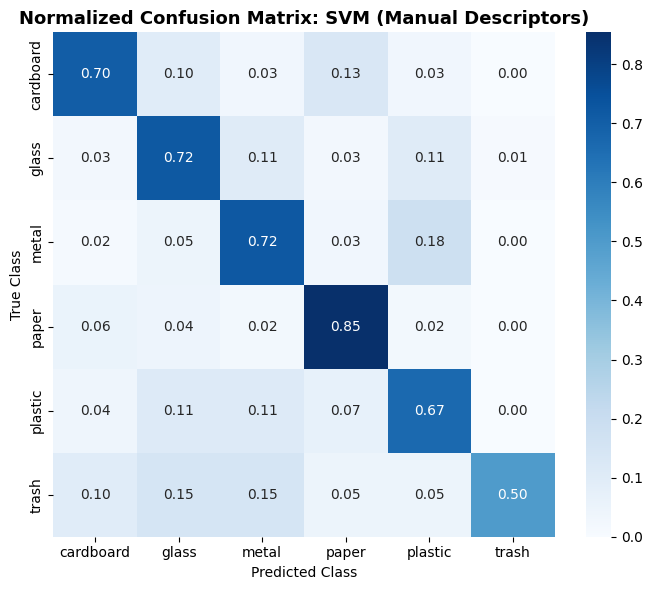

In [4]:
cm = confusion_matrix(y_test, svm_preds, normalize="true")

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Normalized Confusion Matrix: SVM (Manual Descriptors)", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()
